# 04 · Forecast scores, calibration and model risk

**RQ3:** Does the conclusion survive changing the loss and dependence assumptions?
The frozen benchmark has an informative ranking reversal. QLIKE remains primary;
the quadratic score is retained with paired uncertainty, rather than promoted
after seeing favorable outcomes.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from spde_covariance.empirical_research import load_research_evidence

evidence = load_research_evidence(Path("../experiments/results/shfe-research"))
print(evidence["protocol"]["status"])
print("Numerical source:", evidence["manifest"]["git_revision"])
print("Original baseline source:", evidence["protocol"]["baseline_source_revision"])
assert evidence["protocol"]["baseline_summary_sha256"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
LABELS = {
    "outright_3m": "Outright",
    "spread_3m_6m": "Spread",
    "butterfly_3m_6m_9m": "Butterfly",
    "factor": "Factor only",
    "joint": "Factor + residual",
    "source": "Source C (original)",
    "direct": "Direct",
    "unhedged": "Unhedged",
    "factor_adjusted": "Transport adjusted",
    "factor_unadjusted": "Unadjusted",
    "spde_local": "Local source C",
    "shrinkage": "Direct + shrinkage",
    "joint_calendar": "Joint / calendar",
    "joint_session": "Joint / session",
    "bootstrap_percentile_95": "95% block range",
    "bootstrap_standard_error": "Block SE",
    "realized_over_predicted_second_moment": "Realized / predicted",
    "predicted_rms_cny": "Forecast RMS (CNY)",
    "realized_rms_cny": "Realized RMS (CNY)",
    "mean_position_change_proxy": "Position-change proxy",
    "training_count_min_median_max": "Training count (min/median/max)",
    "minimum_relative_forecast_eigenvalue": "Min relative eigenvalue",
    "maximum_exact_transport_identity_absolute_error": "Max transport error",
    "all_forecast_psd_within_roundoff": "PSD within roundoff",
}


def readable_label(value):
    return LABELS.get(value, value.replace("_", " "))


def display_value(value):
    if value is None:
        return "Unavailable"
    if isinstance(value, float):
        return f"{value:.4g}"
    if isinstance(value, (list, tuple)):
        return "[" + ", ".join((display_value(v) for v in value)) + "]"
    if isinstance(value, dict):
        return "; ".join((f"{readable_label(k)}: {display_value(v)}" for k, v in value.items()))
    return readable_label(value) if isinstance(value, str) else str(value)


def table(rows, columns):
    cells = [[readable_label(c) for c in columns]] + [
        [display_value(r.get(c)) for c in columns] for r in rows
    ]
    widths = [max((len(row[i]) for row in cells)) for i in range(len(columns))]
    for row in cells:
        print(" | ".join((v.ljust(w) for v, w in zip(row, widths, strict=True))))

exploratory development on inspected 2024–2025 data
Numerical source: a2f99054886b3154a311665cee7cacd8e6af483c
Original baseline source: d284718c0e465d39886500ab2d85904183266747


## What the scores measure

For $z=Y^2$ and positive forecast $v$,

$$
\ell_Q(v,z)=\log v+z/v,\qquad \ell_2(v,z)=v^2-2vz.
$$

Paired differences are affine in $z$. If $m=\mathbb E[z\mid\mathcal F]$, expected
regrets are $\log(v/m)+m/v-1$ and $(v-m)^2$. Both target the conditional second
moment but weight misspecification differently. QLIKE is sensitive to severe
relative underprediction; quadratic loss weights cash-scale errors. A Gaussian
distribution is not needed. QLIKE uses the original positive floor; quadratic
loss uses the unfloored nonnegative forecast. See
[Patton (2011)](https://public.econ.duke.edu/~ap172/Patton_vol_proxies_JoE_2011.pdf).

In [2]:
scores = evidence["scores"]
protocol = scores["protocol"]
print("Primary loss:", protocol["primary_loss"], "; secondary:", protocol["secondary_loss"])
print(
    "Bootstrap:",
    protocol["primary_bootstrap_block"],
    "sessions per block;",
    protocol["bootstrap_replications"],
    "draws",
)
print(protocol["uncertainty_scope"])
paired = [
    r
    for r in scores["paired_comparisons"]
    if r["stratum"] == "pooled" and r["method"] == "spde_local"
]
table(
    paired,
    [
        "exposure",
        "loss",
        "common_count",
        "mean",
        "bootstrap_standard_error",
        "bootstrap_percentile_95",
    ],
)

Primary loss: qlike ; secondary: quadratic
Bootstrap: 20 sessions per block; 1000 draws
conditional descriptive bootstrap with nominal 95% percentile intervals; not a model confidence interval; no model-selection or multiple-comparison correction
exposure  | loss      | common count | mean       | Block SE  | 95% block range         
Butterfly | qlike     | 484          | 5.882      | 1.874     | [2.623, 9.859]          
Butterfly | quadratic | 484          | -1.647e+12 | 9.286e+11 | [-3.478e+12, 1.887e+11] 
Outright  | qlike     | 484          | 0.1303     | 0.136     | [-0.154, 0.3938]        
Outright  | quadratic | 484          | -7.444e+12 | 5.232e+13 | [-1.119e+14, 8.761e+13] 
Spread    | qlike     | 484          | 0.953      | 0.4261    | [0.1878, 1.839]         
Spread    | quadratic | 484          | -3.907e+11 | 1.22e+11  | [-6.654e+11, -1.766e+11]


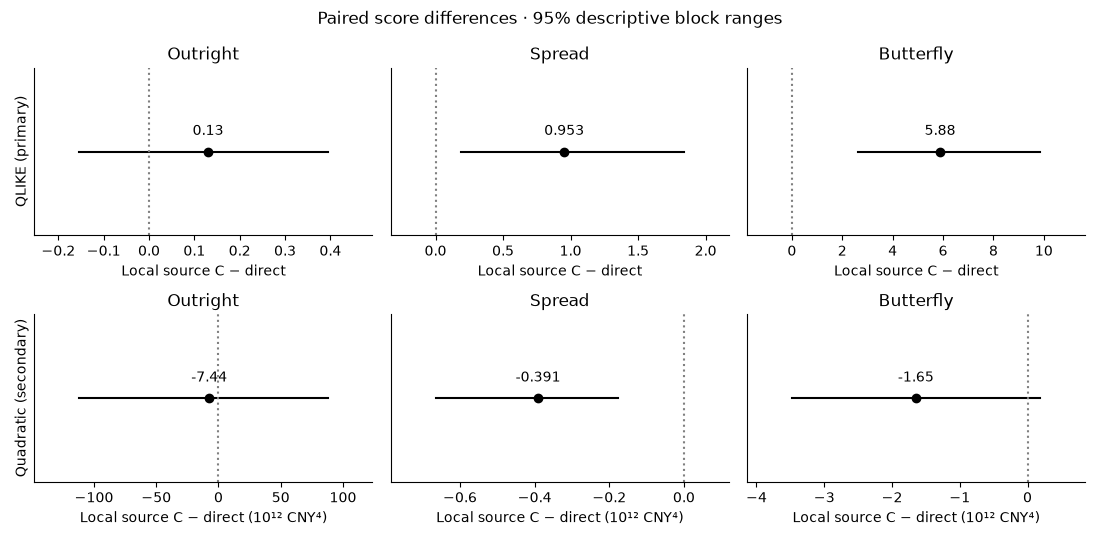

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(11, 5.4))
exposures = ["outright_3m", "spread_3m_6m", "butterfly_3m_6m_9m"]
for column, exposure in enumerate(exposures):
    for row_index, (loss, scale) in enumerate([("qlike", 1.0), ("quadratic", 1000000000000.0)]):
        ax = axes[row_index, column]
        result = next((r for r in paired if r["loss"] == loss and r["exposure"] == exposure))
        if result["available"]:
            lo, hi = np.asarray(result["bootstrap_percentile_95"]) / scale
            mean = result["mean"] / scale
            ax.plot([lo, hi], [0, 0], color="black", linewidth=1.5)
            ax.plot(mean, 0, "o", color="black")
            ax.annotate(
                f"{mean:.3g}", (mean, 0), xytext=(0, 12), textcoords="offset points", ha="center"
            )
        ax.axvline(0, color="0.5", linestyle=":")
        ax.set(
            yticks=[],
            ylim=(-0.7, 0.7),
            title=readable_label(exposure),
            xlabel="Local source C − direct" + (" (10¹² CNY⁴)" if scale > 1 else ""),
        )
        ax.margins(x=0.18)
        if column == 0:
            ax.set_ylabel("QLIKE (primary)" if row_index == 0 else "Quadratic (secondary)")
fig.suptitle("Paired score differences · 95% descriptive block ranges", fontsize=12)
fig.tight_layout()
plt.show()

## Dependence, calibration and period sensitivity

Each panel above uses its own horizontal scale. Every exposure and both losses
remain visible: the spread ranking reversal is not compressed by outright
uncertainty. Negative differences favor the local source model.

Circular moving blocks resample chronologically ordered paired scored sessions.
The number of sessions is not a Monte Carlo replication count. The percentile
ranges are descriptive and do not correct for the many explored comparisons.
Calibration bins are based on forecast risk, and realized-outcome strata are
explicitly ex post. Neither is used to tune a policy on the evaluation outcomes.

In [4]:
sensitivity = [
    r
    for r in scores["block_sensitivity"]
    if r["method"] == "spde_local" and r["exposure"] == "spread_3m_6m"
]
table(
    sensitivity,
    [
        "loss",
        "requested_block_length",
        "mean",
        "bootstrap_standard_error",
        "bootstrap_percentile_95",
    ],
)
table(
    [
        r
        for r in scores["method_summaries"]
        if r["method"] in ("spde_local", "direct") and r["stratum"] == "year"
    ],
    ["group", "exposure", "method", "count", "mean_qlike", "risk_ratio"],
)
table(
    [
        r
        for r in scores["method_summaries"]
        if r["method"] in ("spde_local", "direct") and r["stratum"] == "calendar_gap"
    ],
    ["group", "exposure", "method", "count", "mean_qlike", "risk_ratio"],
)
table(
    [r for r in scores["realized_outcome_strata"] if r["method"] in ("spde_local", "direct")],
    ["realized_squared_pnl_third", "exposure", "method", "count", "mean_qlike", "risk_ratio"],
)

loss      | requested block length | mean       | Block SE  | 95% block range         
qlike     | 5                      | 0.953      | 0.3895    | [0.2745, 1.786]         
qlike     | 10                     | 0.953      | 0.4169    | [0.262, 1.871]          
qlike     | 20                     | 0.953      | 0.4261    | [0.1878, 1.839]         
qlike     | 40                     | 0.953      | 0.442     | [0.1735, 1.891]         
quadratic | 5                      | -3.907e+11 | 9.065e+10 | [-5.771e+11, -2.256e+11]
quadratic | 10                     | -3.907e+11 | 1.078e+11 | [-6.227e+11, -1.974e+11]
quadratic | 20                     | -3.907e+11 | 1.22e+11  | [-6.654e+11, -1.766e+11]
quadratic | 40                     | -3.907e+11 | 1.168e+11 | [-6.36e+11, -1.752e+11] 
group | exposure  | method         | count | mean qlike | risk ratio
2024  | Butterfly | Direct         | 241   | 14.83      | 0.5964    
2024  | Butterfly | Local source C | 241   | 18.89      | 5.601     
2025  | Bu

exposure  | forecast variance quintile | count | Forecast RMS (CNY) | Realized RMS (CNY) | risk ratio
Butterfly | 1                          | 97    | 276.1              | 829.8              | 9.03      
Butterfly | 2                          | 97    | 313.2              | 1201               | 14.71     
Butterfly | 3                          | 96    | 338                | 1144               | 11.44     
Butterfly | 4                          | 97    | 375.5              | 1007               | 7.191     
Butterfly | 5                          | 97    | 614.2              | 1071               | 3.04      
Outright  | 1                          | 97    | 2136               | 3333               | 2.435     
Outright  | 2                          | 97    | 2475               | 3458               | 1.952     
Outright  | 3                          | 96    | 2759               | 3232               | 1.372     
Outright  | 4                          | 97    | 3043               | 2383        

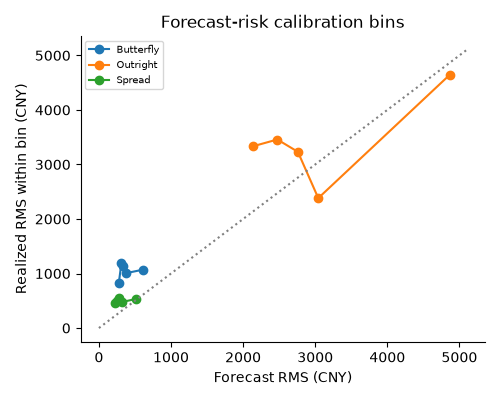

In [5]:
rows = [r for r in scores["calibration_bins"] if r["method"] == "spde_local"]
table(
    rows,
    [
        "exposure",
        "forecast_variance_quintile",
        "count",
        "predicted_rms_cny",
        "realized_rms_cny",
        "risk_ratio",
    ],
)
fig, ax = plt.subplots(figsize=(5, 4))
for exposure in sorted({r["exposure"] for r in rows}):
    selected = [r for r in rows if r["exposure"] == exposure and r["available"]]
    ax.plot(
        [r["predicted_rms_cny"] for r in selected],
        [r["realized_rms_cny"] for r in selected],
        "o-",
        label=readable_label(exposure),
    )
limit = ax.get_xlim()[1]
ax.plot([0, limit], [0, limit], ":", color="0.5")
ax.set(
    xlabel="Forecast RMS (CNY)",
    ylabel="Realized RMS within bin (CNY)",
    title="Forecast-risk calibration bins",
)
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

## Influential paired differences

The following diagnostic removes the largest 1% or 5% of absolute paired score
differences. It measures influence, not a preferred cleaned evaluation sample.
No dates or individual market outcomes are exported; small cells are suppressed.

In [6]:
table(
    [r for r in scores["score_influence"] if r["method"] == "spde_local"],
    [
        "exposure",
        "loss",
        "fraction",
        "full_mean_difference",
        "remaining_mean_difference",
        "removed_absolute_difference_share",
    ],
)
table(
    [r for r in scores["availability"] if r["method"] in ("direct", "spde_local")],
    list(scores["availability"][0].keys()),
)

exposure  | loss      | fraction | full mean difference | remaining mean difference | removed absolute difference share
Butterfly | qlike     | 0.01     | 5.882                | 3.504                     | 0.3199                           
Butterfly | qlike     | 0.05     | 5.882                | 1.827                     | 0.5497                           
Butterfly | quadratic | 0.01     | -1.647e+12           | -2.142e+12                | 0.1979                           
Butterfly | quadratic | 0.05     | -1.647e+12           | -9.922e+11                | 0.5159                           
Outright  | qlike     | 0.01     | 0.1303               | 0.1239                    | 0.2445                           
Outright  | qlike     | 0.05     | 0.1303               | 0.06199                   | 0.4811                           
Outright  | quadratic | 0.01     | -7.444e+12           | -9.442e+12                | 0.3379                           
Outright  | quadratic | 0.05     | -7.44

## Interpretation and next decision

The spread difference is +0.953 under primary QLIKE (bootstrap range
[0.188, 1.839]) but −0.391×10¹² CNY⁴ under quadratic loss (range
[−0.665, −0.177]×10¹²). Outright and butterfly quadratic ranges include zero.

Read score ranking, calibration and uncertainty together. Favorable quadratic
loss on one exposure does not remove a QLIKE or underprediction failure. The
matched-window experiment addresses attribution; the joint model addresses
missing risk. An uninspected confirmation period is needed for a revised policy.

## Reproduction and research boundary

This notebook reads checksummed aggregate evidence, not raw exchange files.
The numerical algorithms are in `spde_covariance`; use the
[protocol](../docs/empirical-research-protocol.md) to rerun local calibration.
Execute this notebook with `uv run python scripts/check_notebook.py notebooks/04_forecast_scores_and_model_risk.ipynb`.

The original historical benchmark remains fixed. New analyses on the inspected
2024–2025 period are exploratory, even though forecast issuance is past-only.
No final untouched confirmation period, executable trading backtest or physical
forcing identification is claimed. See the [roadmap](../README.md).

The displayed tables emphasize the primary comparisons. Complete sensitivity,
availability and numerical diagnostics remain in the checksummed aggregate files:
[data](../experiments/results/shfe-research/data.json),
[representation](../experiments/results/shfe-research/representation.json),
[attribution](../experiments/results/shfe-research/attribution.json),
[scores](../experiments/results/shfe-research/scores.json), and
[joint risk / hedging](../experiments/results/shfe-research/joint.json).